# 📊 Dataset Visualisation
A quick visual overview of both the **Anime** and **Movie** datasets used in the recommender app.

Covers: score/rating distributions, genre breakdowns, type/language splits, score-vs-popularity relationships, and top entries.

In [1]:
import os
import warnings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

warnings.filterwarnings('ignore')
sns.set_theme(style='darkgrid', palette='muted')
plt.rcParams.update({'figure.dpi': 120, 'figure.facecolor': '#1a1a2e', 'axes.facecolor': '#16213e',
                     'axes.labelcolor': 'white', 'xtick.color': 'white', 'ytick.color': 'white',
                     'text.color': 'white', 'axes.titlecolor': 'white', 'grid.color': '#2a2a4a'})

ANIME_PATH = 'data/anime-dataset-2026.csv'
MOVIE_PATH = 'data/TMDB_movie_dataset_v11.csv'

print('Libraries loaded.')

Libraries loaded.


---
# 🎌 Part 1 — Anime Dataset

In [2]:
anime = pd.read_csv(ANIME_PATH)
anime.rename(columns={
    'Name': 'name', 'Score': 'score', 'Rank': 'rank', 'Type': 'type',
    'Genres': 'genres', 'Synopsis': 'synopsis', 'Image URL': 'image_url',
    'Studios': 'studios', 'Source': 'source', 'Episodes': 'episodes',
    'Popularity': 'popularity', 'Members': 'members', 'Favorites': 'favorites',
    'Rating': 'rating', 'Premiered': 'premiered', 'Status': 'status',
}, inplace=True)

anime['score'] = pd.to_numeric(anime['score'], errors='coerce')
anime['rank'] = pd.to_numeric(anime['rank'], errors='coerce')
anime['episodes'] = pd.to_numeric(anime['episodes'], errors='coerce')
anime['members'] = pd.to_numeric(anime['members'], errors='coerce')
anime['favorites'] = pd.to_numeric(anime['favorites'], errors='coerce')
anime['popularity'] = pd.to_numeric(anime['popularity'], errors='coerce')

print(f'Rows: {len(anime):,}  |  Columns: {len(anime.columns)}')
anime.head(3)

Rows: 30,763  |  Columns: 24


,anime_id,name,English name,Other name,score,genres,synopsis,type,episodes,Aired,...,studios,source,Duration,rating,rank,popularity,favorites,Scored By,members,image_url
0,1,Cowboy Bebop,Cowboy Bebop,カウボーイビバップ,8.75,"Action, Award Winning, Sci-Fi, Adult Cast, Space","Crime is timeless. By the year 2071, humanity ...",TV,26.0,"Apr 3, 1998 to Apr 24, 1999",...,Sunrise,Original,24 min. per ep.,R - 17+ (violence & profanity),50.0,41,90976,1077271,2089081,https://cdn.myanimelist.net/images/anime/4/196...
1,5,Cowboy Bebop: Tengoku no Tobira,Cowboy Bebop: The Movie,カウボーイビバップ 天国の扉,8.38,"Action, Sci-Fi, Adult Cast, Space","Another day, another bounty—such is the life o...",Movie,1.0,"Sep 1, 2001",...,Bones,Original,1 hr. 55 min.,R - 17+ (violence & profanity),252.0,663,1827,234731,417292,https://cdn.myanimelist.net/images/anime/1439/...
2,6,Trigun,Trigun,トライガン,8.22,"Action, Adventure, Sci-Fi, Adult Cast, Shounen","Vash the Stampede is the man with a $$60,000,0...",TV,26.0,"Apr 1, 1998 to Sep 30, 1998",...,Madhouse,Manga,24 min. per ep.,PG-13 - Teens 13 or older,433.0,268,17956,405835,846067,https://cdn.myanimelist.net/images/anime/1130/...


## 1.1 Score Distribution

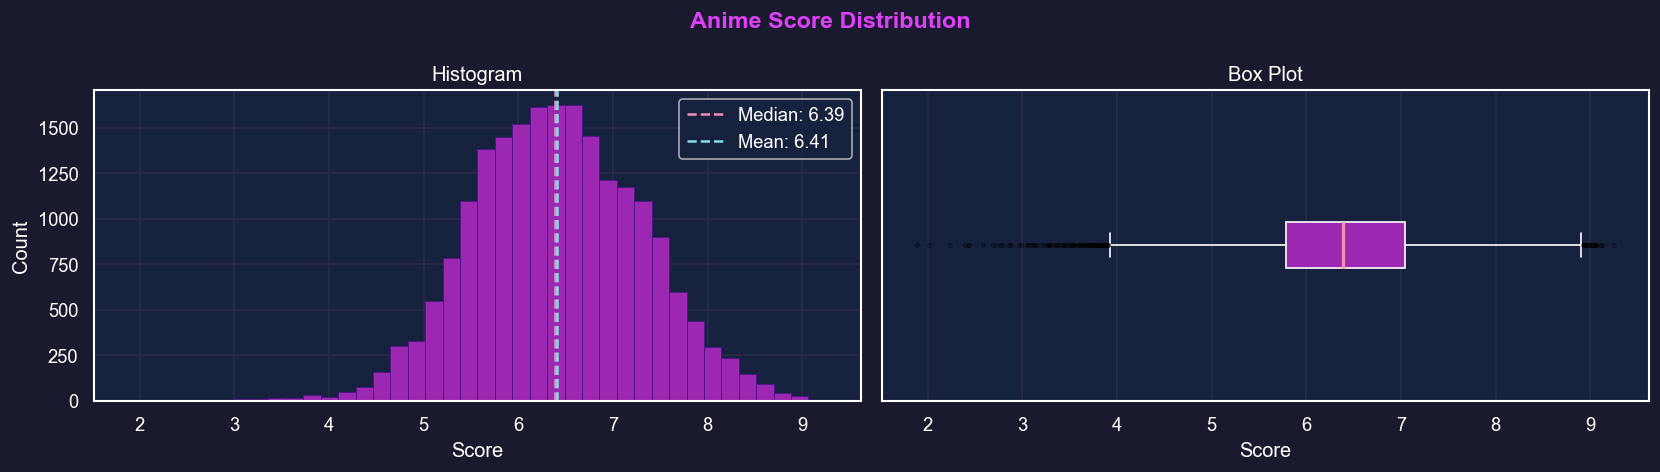

Scored entries: 20,358 / 30,763
count    20358.00
mean         6.41
std          0.89
min          1.89
25%          5.79
50%          6.39
75%          7.04
max          9.25


In [3]:
scored = anime['score'].dropna()

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
fig.suptitle('Anime Score Distribution', fontsize=14, fontweight='bold', color='#e040fb')

axes[0].hist(scored, bins=40, color='#9c27b0', edgecolor='#4a148c', linewidth=0.5)
axes[0].set_title('Histogram')
axes[0].set_xlabel('Score')
axes[0].set_ylabel('Count')
axes[0].axvline(scored.median(), color='#f48fb1', linestyle='--', linewidth=1.5, label=f'Median: {scored.median():.2f}')
axes[0].axvline(scored.mean(), color='#80deea', linestyle='--', linewidth=1.5, label=f'Mean: {scored.mean():.2f}')
axes[0].legend()

axes[1].boxplot(scored, vert=False, patch_artist=True,
                boxprops=dict(facecolor='#9c27b0', color='white'),
                medianprops=dict(color='#f48fb1', linewidth=2),
                whiskerprops=dict(color='white'), capprops=dict(color='white'),
                flierprops=dict(marker='o', color='#ce93d8', markersize=2, alpha=0.4))
axes[1].set_title('Box Plot')
axes[1].set_xlabel('Score')
axes[1].set_yticks([])

plt.tight_layout()
plt.show()
print(f"Scored entries: {len(scored):,} / {len(anime):,}")
print(scored.describe().round(2).to_string())

## 1.2 Top 20 Genres

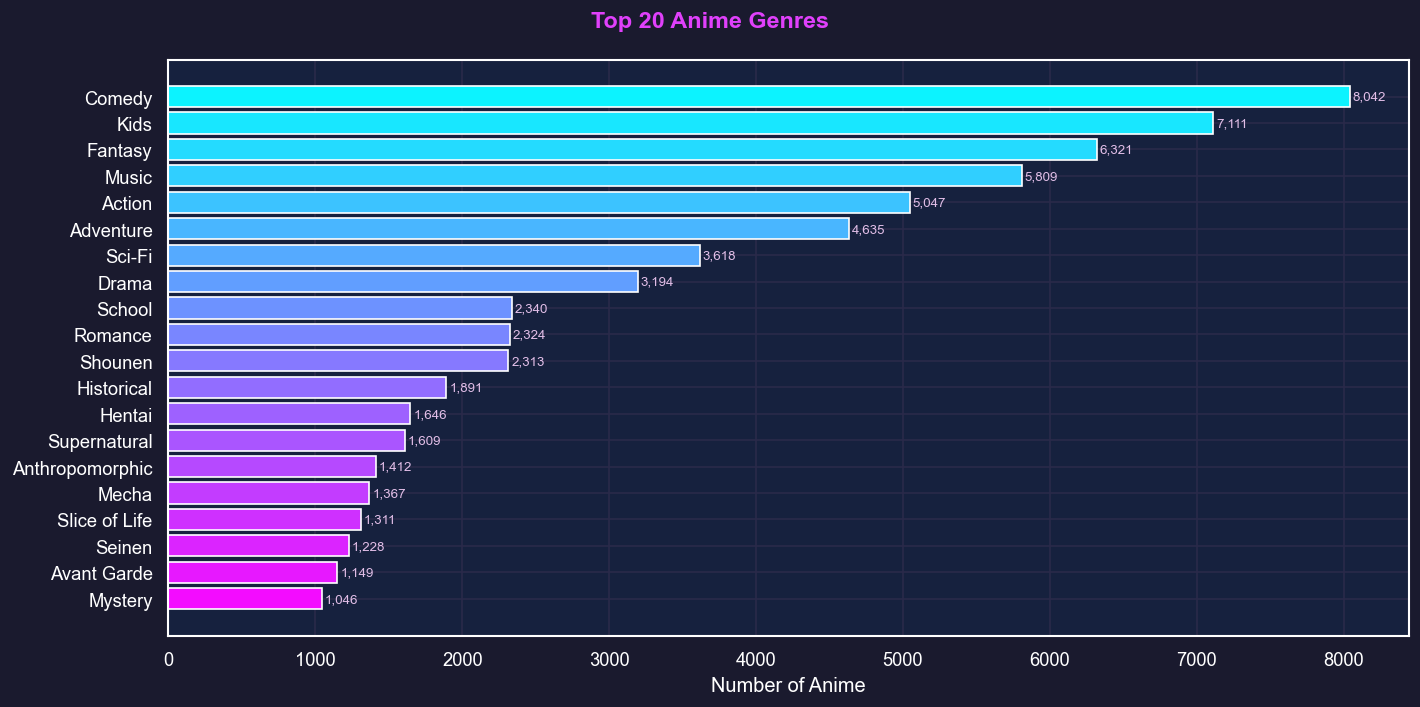

In [4]:
genre_counts = (
    anime['genres'].dropna()
    .str.split(', ')
    .explode()
    .str.strip()
    .value_counts()
    .head(20)
)

fig, ax = plt.subplots(figsize=(12, 6))
fig.suptitle('Top 20 Anime Genres', fontsize=14, fontweight='bold', color='#e040fb')
colors = sns.color_palette('cool', len(genre_counts))
bars = ax.barh(genre_counts.index[::-1], genre_counts.values[::-1], color=colors[::-1])
for bar, val in zip(bars, genre_counts.values[::-1]):
    ax.text(bar.get_width() + 20, bar.get_y() + bar.get_height() / 2,
            f'{val:,}', va='center', fontsize=8, color='#e1bee7')
ax.set_xlabel('Number of Anime')
ax.set_title('')
plt.tight_layout()
plt.show()

## 1.3 Anime Type Breakdown

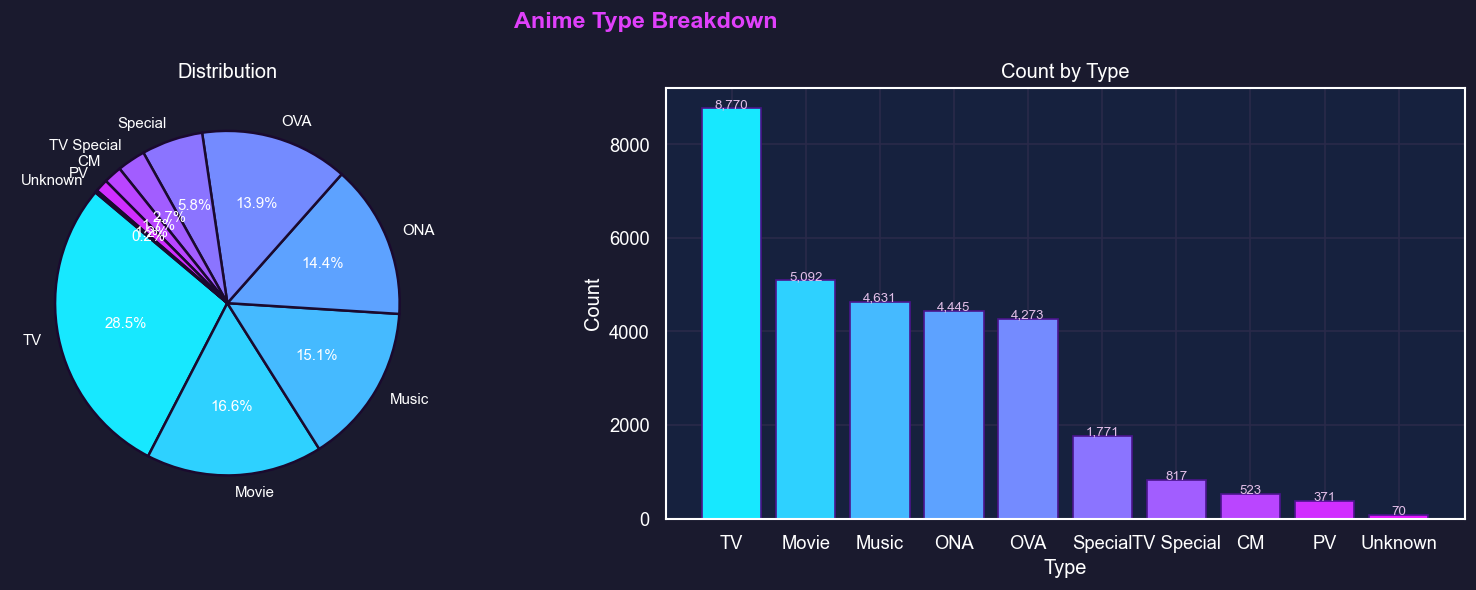

In [5]:
type_counts = anime['type'].value_counts().dropna()
type_counts = type_counts[type_counts.index != 'UNKNOWN']

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Anime Type Breakdown', fontsize=14, fontweight='bold', color='#e040fb')

colors = sns.color_palette('cool', len(type_counts))
axes[0].pie(type_counts.values, labels=type_counts.index, autopct='%1.1f%%',
            colors=colors, startangle=140,
            wedgeprops=dict(edgecolor='#1a0a2e', linewidth=1.5),
            textprops=dict(color='white', fontsize=9))
axes[0].set_title('Distribution')

axes[1].bar(type_counts.index, type_counts.values, color=colors, edgecolor='#4a148c')
axes[1].set_title('Count by Type')
axes[1].set_xlabel('Type')
axes[1].set_ylabel('Count')
for i, (idx, val) in enumerate(type_counts.items()):
    axes[1].text(i, val + 20, f'{val:,}', ha='center', fontsize=8, color='#e1bee7')

plt.tight_layout()
plt.show()

## 1.4 Score by Type

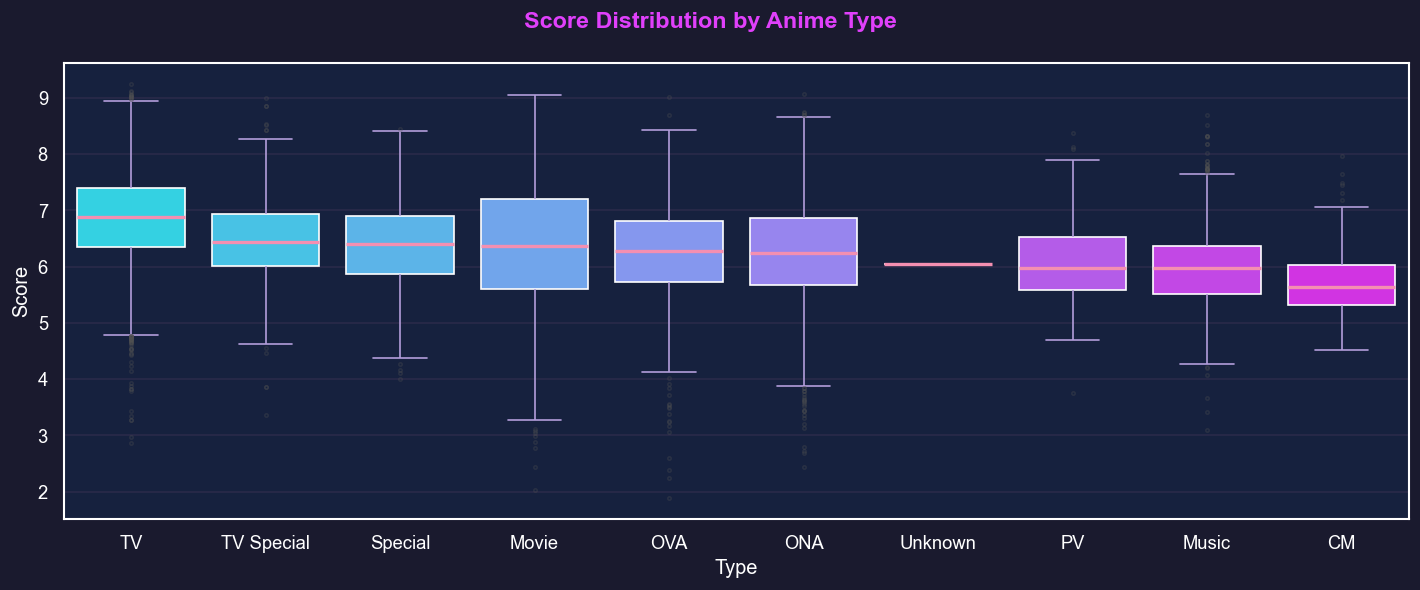

In [6]:
valid_types = anime[anime['type'].notna() & (anime['type'] != 'UNKNOWN') & anime['score'].notna()]
type_order = valid_types.groupby('type')['score'].median().sort_values(ascending=False).index

fig, ax = plt.subplots(figsize=(12, 5))
fig.suptitle('Score Distribution by Anime Type', fontsize=14, fontweight='bold', color='#e040fb')
sns.boxplot(data=valid_types, x='type', y='score', order=type_order,
            palette='cool', ax=ax,
            boxprops=dict(edgecolor='white'),
            medianprops=dict(color='#f48fb1', linewidth=2),
            whiskerprops=dict(color='#b39ddb'),
            capprops=dict(color='#b39ddb'),
            flierprops=dict(marker='o', markersize=2, alpha=0.3, color='#ce93d8'))
ax.set_xlabel('Type')
ax.set_ylabel('Score')
plt.tight_layout()
plt.show()

## 1.5 Top 15 Anime by Members

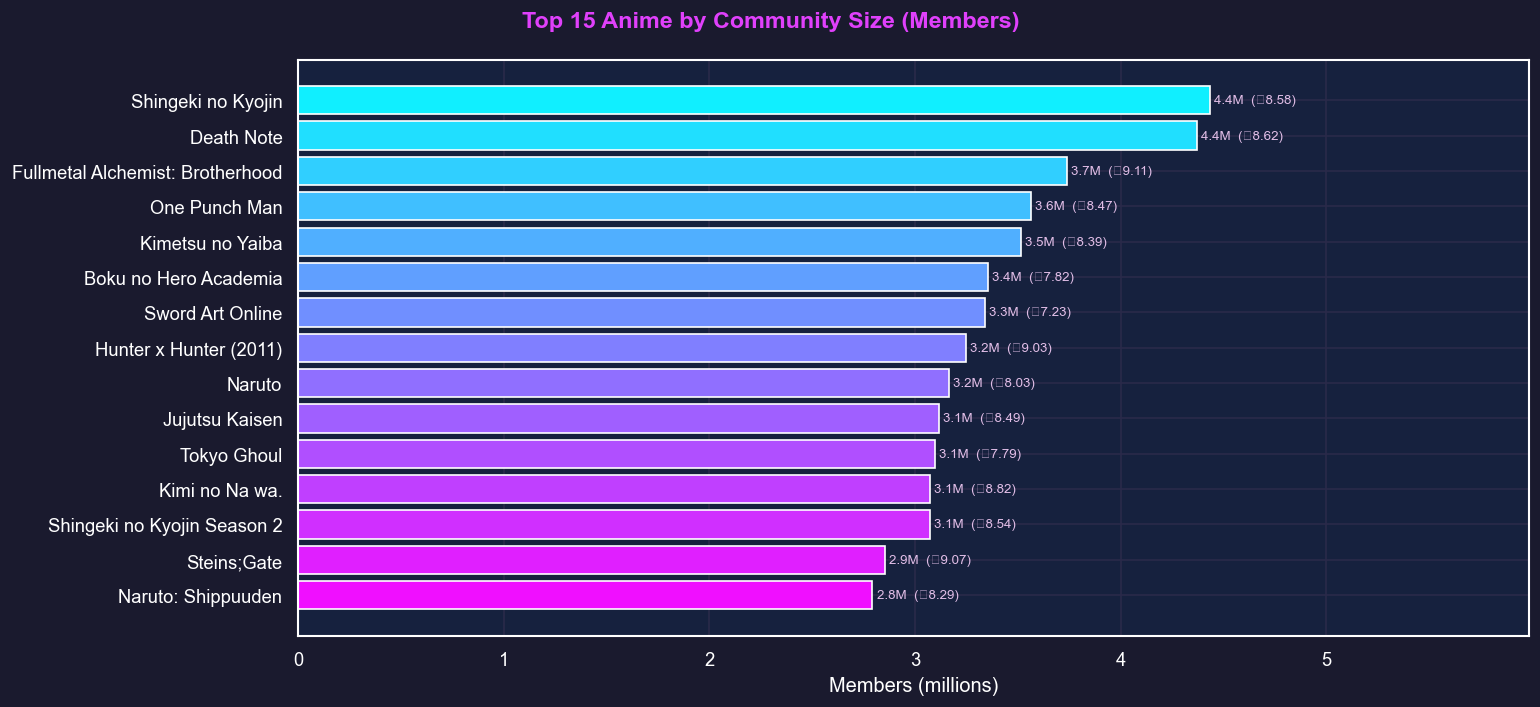

In [7]:
top_members = anime.nlargest(15, 'members')[['name', 'score', 'members', 'type']].reset_index(drop=True)

fig, ax = plt.subplots(figsize=(13, 6))
fig.suptitle('Top 15 Anime by Community Size (Members)', fontsize=14, fontweight='bold', color='#e040fb')
colors = sns.color_palette('cool', 15)
bars = ax.barh(top_members['name'][::-1], top_members['members'][::-1] / 1e6, color=colors[::-1])
for bar, row in zip(bars, top_members.iloc[::-1].itertuples()):
    ax.text(bar.get_width() + 0.02, bar.get_y() + bar.get_height() / 2,
            f'{row.members/1e6:.1f}M  (⭐{row.score})', va='center', fontsize=8, color='#e1bee7')
ax.set_xlabel('Members (millions)')
ax.set_xlim(0, top_members['members'].max() / 1e6 * 1.35)
plt.tight_layout()
plt.show()

## 1.6 Score vs Popularity

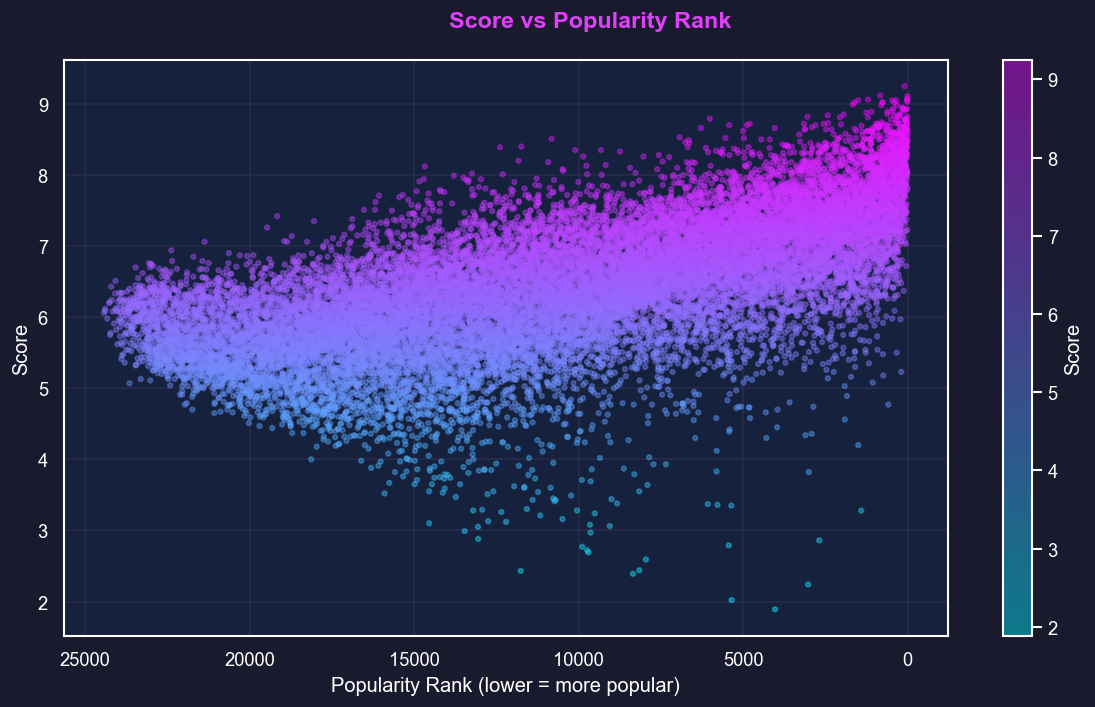

In [8]:
scatter_data = anime[anime['score'].notna() & anime['popularity'].notna() & (anime['score'] > 0)]

fig, ax = plt.subplots(figsize=(10, 6))
fig.suptitle('Score vs Popularity Rank', fontsize=14, fontweight='bold', color='#e040fb')
sc = ax.scatter(scatter_data['popularity'], scatter_data['score'],
                alpha=0.4, s=8, c=scatter_data['score'], cmap='cool')
plt.colorbar(sc, ax=ax, label='Score')
ax.set_xlabel('Popularity Rank (lower = more popular)')
ax.set_ylabel('Score')
ax.invert_xaxis()
plt.tight_layout()
plt.show()

---
# 🎬 Part 2 — Movie Dataset

In [9]:
movies_raw = pd.read_csv(MOVIE_PATH)
movies_raw['vote_average'] = pd.to_numeric(movies_raw['vote_average'], errors='coerce').fillna(0)
movies_raw['vote_count'] = pd.to_numeric(movies_raw['vote_count'], errors='coerce').fillna(0)
movies_raw['revenue'] = pd.to_numeric(movies_raw['revenue'], errors='coerce').fillna(0)
movies_raw['runtime'] = pd.to_numeric(movies_raw['runtime'], errors='coerce')
movies_raw['budget'] = pd.to_numeric(movies_raw['budget'], errors='coerce').fillna(0)
movies_raw['title'] = movies_raw['title'].fillna('').astype(str)

# Same quality filter used by the recommender
movies = movies_raw[
    (movies_raw['title'].str.strip() != '') &
    (movies_raw['status'].str.lower() == 'released') &
    (movies_raw['vote_count'] >= 50)
].reset_index(drop=True)

print(f'Raw rows: {len(movies_raw):,}  |  After quality filter: {len(movies):,}')
movies.head(3)

Raw rows: 1,525,723  |  After quality filter: 27,981


,id,title,vote_average,vote_count,status,release_date,revenue,runtime,adult,backdrop_path,...,original_title,overview,popularity,poster_path,tagline,genres,production_companies,production_countries,spoken_languages,keywords
0,27205,Inception,8.364,34495,Released,2010-07-15,825532764,148,False,/8ZTVqvKDQ8emSGUEMjsS4yHAwrp.jpg,...,Inception,"Cobb, a skilled thief who commits corporate es...",83.952,/oYuLEt3zVCKq57qu2F8dT7NIa6f.jpg,Your mind is the scene of the crime.,"Action, Science Fiction, Adventure","Legendary Pictures, Syncopy, Warner Bros. Pict...","United Kingdom, United States of America","English, French, Japanese, Swahili","rescue, mission, dream, airplane, paris, franc..."
1,157336,Interstellar,8.417,32571,Released,2014-11-05,701729206,169,False,/pbrkL804c8yAv3zBZR4QPEafpAR.jpg,...,Interstellar,The adventures of a group of explorers who mak...,140.241,/gEU2QniE6E77NI6lCU6MxlNBvIx.jpg,Mankind was born on Earth. It was never meant ...,"Adventure, Drama, Science Fiction","Legendary Pictures, Syncopy, Lynda Obst Produc...","United Kingdom, United States of America",English,"rescue, future, spacecraft, race against time,..."
2,155,The Dark Knight,8.512,30619,Released,2008-07-16,1004558444,152,False,/nMKdUUepR0i5zn0y1T4CsSB5chy.jpg,...,The Dark Knight,Batman raises the stakes in his war on crime. ...,130.643,/qJ2tW6WMUDux911r6m7haRef0WH.jpg,Welcome to a world without rules.,"Drama, Action, Crime, Thriller","DC Comics, Legendary Pictures, Syncopy, Isobel...","United Kingdom, United States of America","English, Mandarin","joker, sadism, chaos, secret identity, crime f..."


## 2.1 Rating Distribution

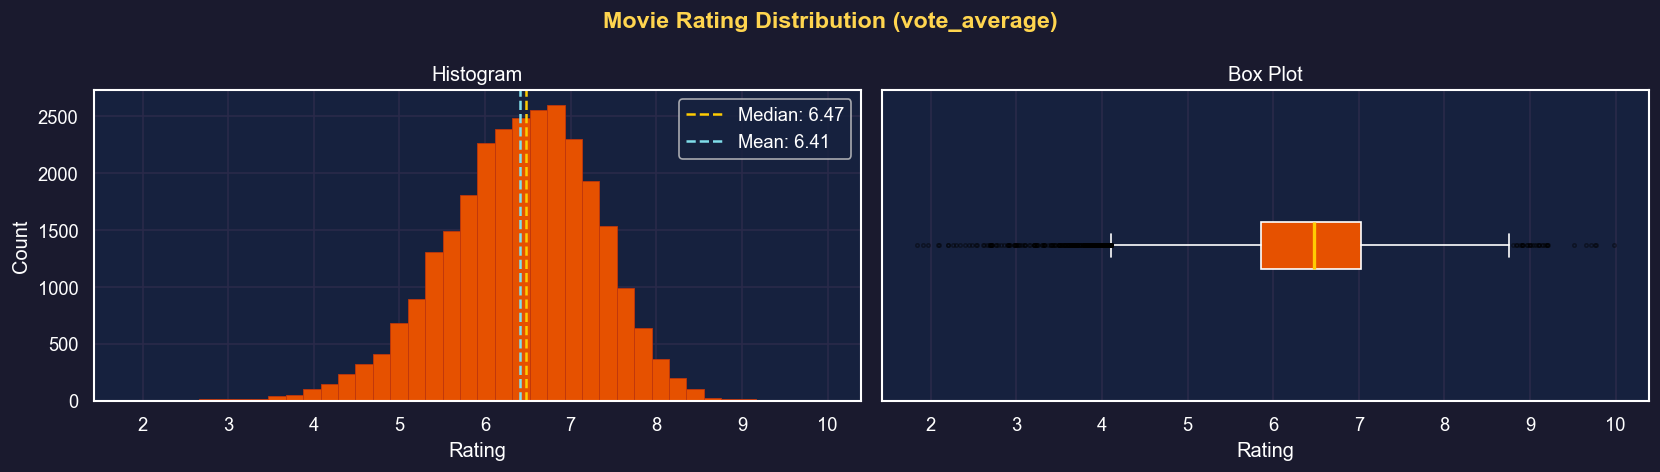

count    27981.00
mean         6.41
std          0.88
min          1.84
25%          5.86
50%          6.47
75%          7.02
max          9.98


In [10]:
rated = movies[movies['vote_average'] > 0]['vote_average']

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
fig.suptitle('Movie Rating Distribution (vote_average)', fontsize=14, fontweight='bold', color='#ffd54f')

axes[0].hist(rated, bins=40, color='#e65100', edgecolor='#bf360c', linewidth=0.5)
axes[0].set_title('Histogram')
axes[0].set_xlabel('Rating')
axes[0].set_ylabel('Count')
axes[0].axvline(rated.median(), color='#ffcc02', linestyle='--', linewidth=1.5, label=f'Median: {rated.median():.2f}')
axes[0].axvline(rated.mean(), color='#80deea', linestyle='--', linewidth=1.5, label=f'Mean: {rated.mean():.2f}')
axes[0].legend()

axes[1].boxplot(rated, vert=False, patch_artist=True,
                boxprops=dict(facecolor='#e65100', color='white'),
                medianprops=dict(color='#ffcc02', linewidth=2),
                whiskerprops=dict(color='white'), capprops=dict(color='white'),
                flierprops=dict(marker='o', color='#ffb74d', markersize=2, alpha=0.4))
axes[1].set_title('Box Plot')
axes[1].set_xlabel('Rating')
axes[1].set_yticks([])

plt.tight_layout()
plt.show()
print(rated.describe().round(2).to_string())

## 2.2 Top 20 Genres

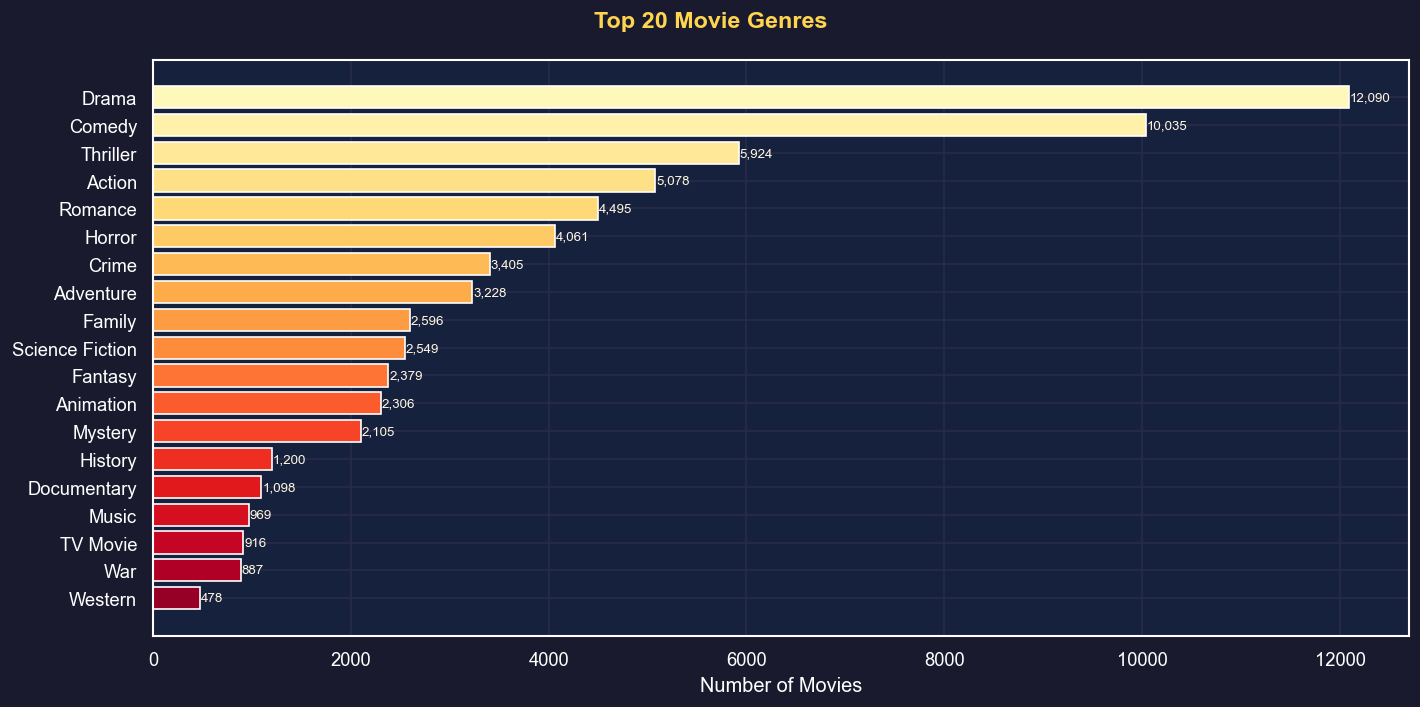

In [11]:
movie_genres = (
    movies['genres'].dropna()
    .str.split(', ')
    .explode()
    .str.strip()
    .value_counts()
    .head(20)
)

fig, ax = plt.subplots(figsize=(12, 6))
fig.suptitle('Top 20 Movie Genres', fontsize=14, fontweight='bold', color='#ffd54f')
colors = sns.color_palette('YlOrRd', len(movie_genres))
bars = ax.barh(movie_genres.index[::-1], movie_genres.values[::-1], color=colors[::-1])
for bar, val in zip(bars, movie_genres.values[::-1]):
    ax.text(bar.get_width() + 10, bar.get_y() + bar.get_height() / 2,
            f'{val:,}', va='center', fontsize=8, color='#fff8e1')
ax.set_xlabel('Number of Movies')
plt.tight_layout()
plt.show()

## 2.3 Top 10 Languages

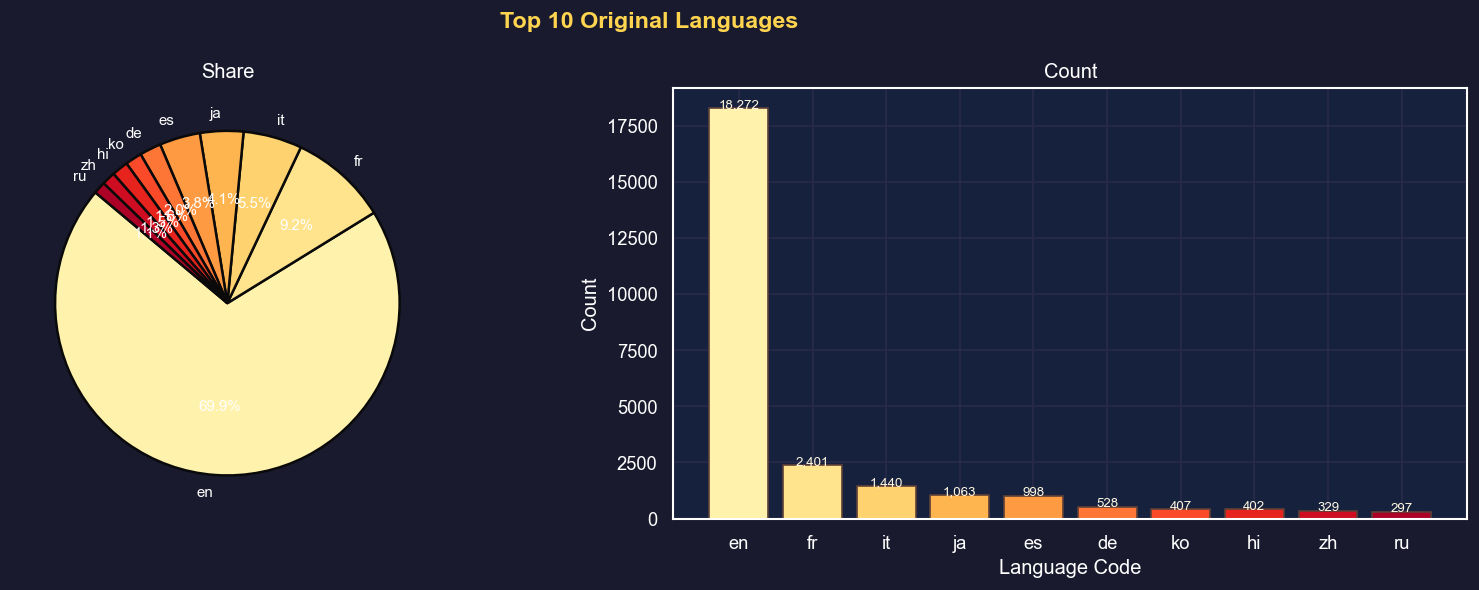

In [12]:
lang_counts = movies['original_language'].value_counts().head(10)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Top 10 Original Languages', fontsize=14, fontweight='bold', color='#ffd54f')
colors = sns.color_palette('YlOrRd', len(lang_counts))

axes[0].pie(lang_counts.values, labels=lang_counts.index, autopct='%1.1f%%',
            colors=colors, startangle=140,
            wedgeprops=dict(edgecolor='#0a0a0a', linewidth=1.5),
            textprops=dict(color='white', fontsize=9))
axes[0].set_title('Share')

axes[1].bar(lang_counts.index, lang_counts.values, color=colors, edgecolor='#5d4037')
axes[1].set_title('Count')
axes[1].set_xlabel('Language Code')
axes[1].set_ylabel('Count')
for i, (idx, val) in enumerate(lang_counts.items()):
    axes[1].text(i, val + 10, f'{val:,}', ha='center', fontsize=8, color='#fff8e1')

plt.tight_layout()
plt.show()

## 2.4 Rating by Language (Top 8)

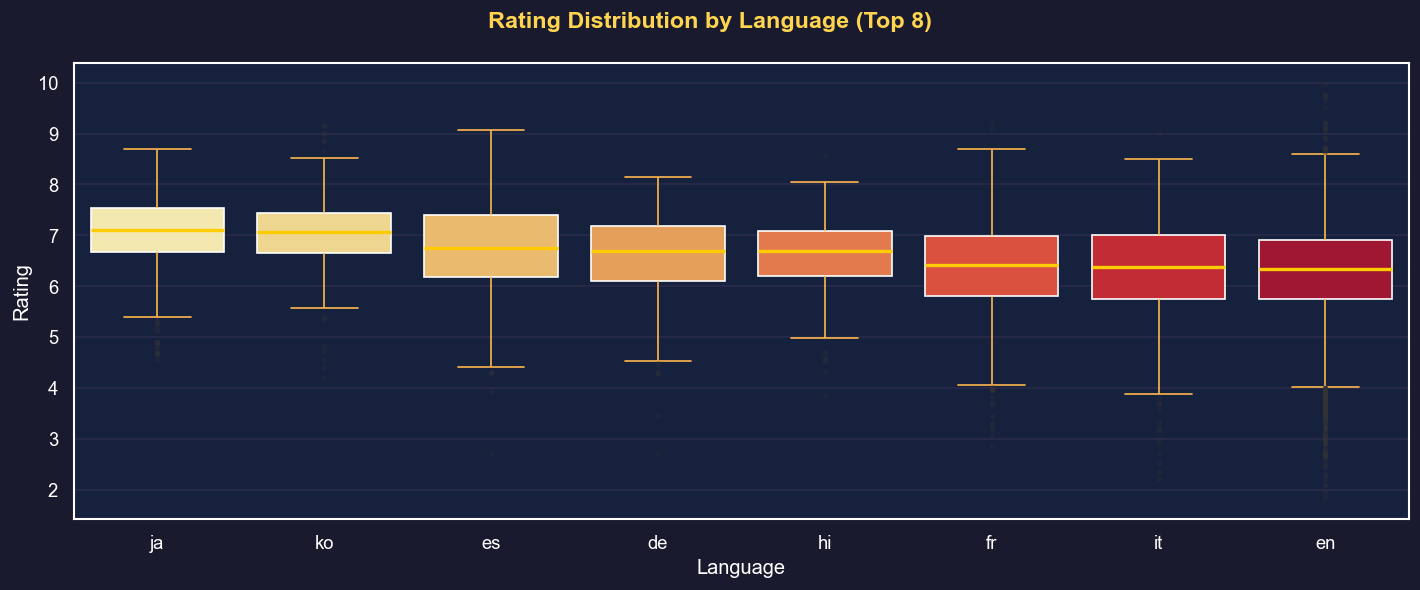

In [13]:
top_langs = movies['original_language'].value_counts().head(8).index
lang_data = movies[movies['original_language'].isin(top_langs) & (movies['vote_average'] > 0)]
lang_order = lang_data.groupby('original_language')['vote_average'].median().sort_values(ascending=False).index

fig, ax = plt.subplots(figsize=(12, 5))
fig.suptitle('Rating Distribution by Language (Top 8)', fontsize=14, fontweight='bold', color='#ffd54f')
sns.boxplot(data=lang_data, x='original_language', y='vote_average', order=lang_order,
            palette='YlOrRd', ax=ax,
            boxprops=dict(edgecolor='white'),
            medianprops=dict(color='#ffcc02', linewidth=2),
            whiskerprops=dict(color='#ffb74d'),
            capprops=dict(color='#ffb74d'),
            flierprops=dict(marker='o', markersize=2, alpha=0.3, color='#ffe082'))
ax.set_xlabel('Language')
ax.set_ylabel('Rating')
plt.tight_layout()
plt.show()

## 2.5 Top 15 Movies by Revenue

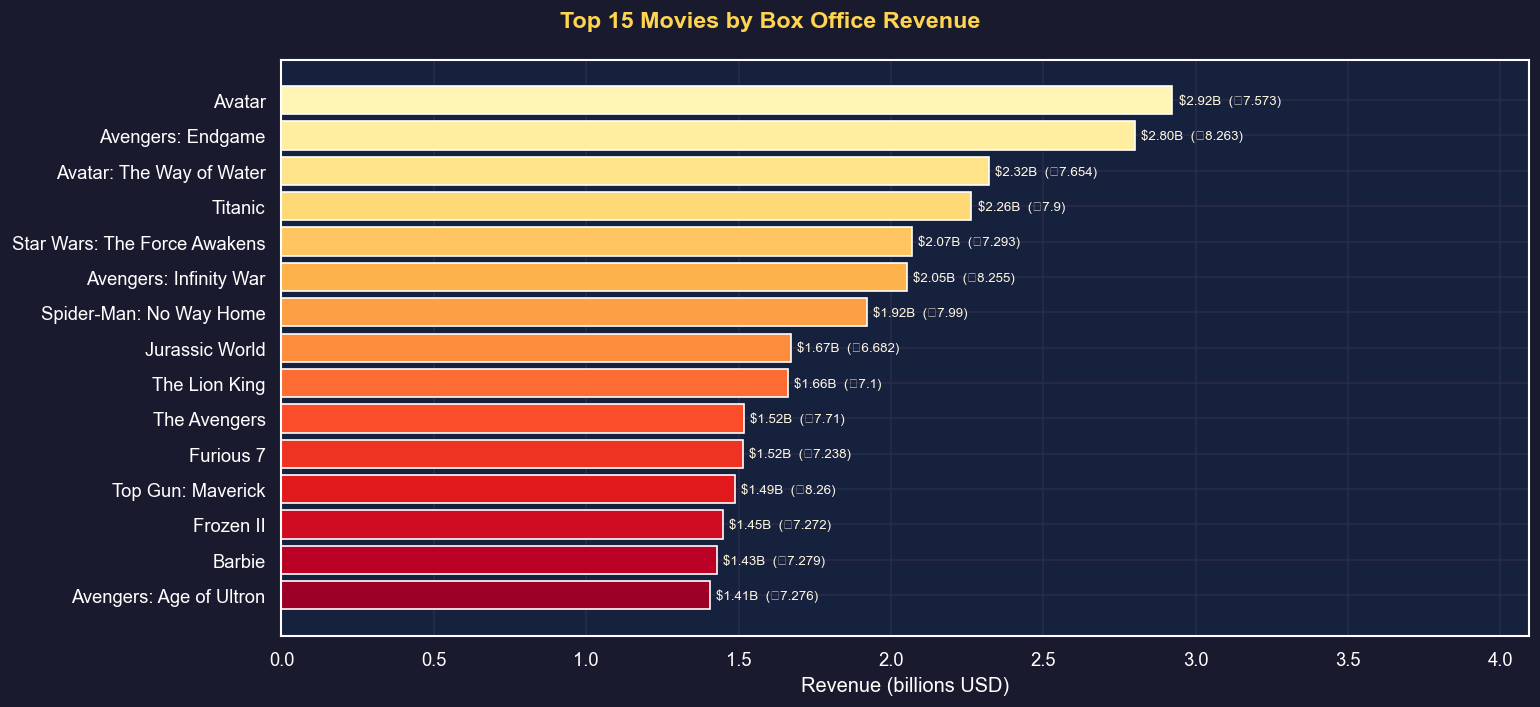

In [14]:
top_revenue = movies[movies['revenue'] > 0].nlargest(15, 'revenue')[['title', 'vote_average', 'revenue', 'release_date']].reset_index(drop=True)

fig, ax = plt.subplots(figsize=(13, 6))
fig.suptitle('Top 15 Movies by Box Office Revenue', fontsize=14, fontweight='bold', color='#ffd54f')
colors = sns.color_palette('YlOrRd', 15)
bars = ax.barh(top_revenue['title'][::-1], top_revenue['revenue'][::-1] / 1e9, color=colors[::-1])
for bar, row in zip(bars, top_revenue.iloc[::-1].itertuples()):
    ax.text(bar.get_width() + 0.02, bar.get_y() + bar.get_height() / 2,
            f'${row.revenue/1e9:.2f}B  (⭐{row.vote_average})', va='center', fontsize=8, color='#fff8e1')
ax.set_xlabel('Revenue (billions USD)')
ax.set_xlim(0, top_revenue['revenue'].max() / 1e9 * 1.4)
plt.tight_layout()
plt.show()

## 2.6 Rating vs Vote Count

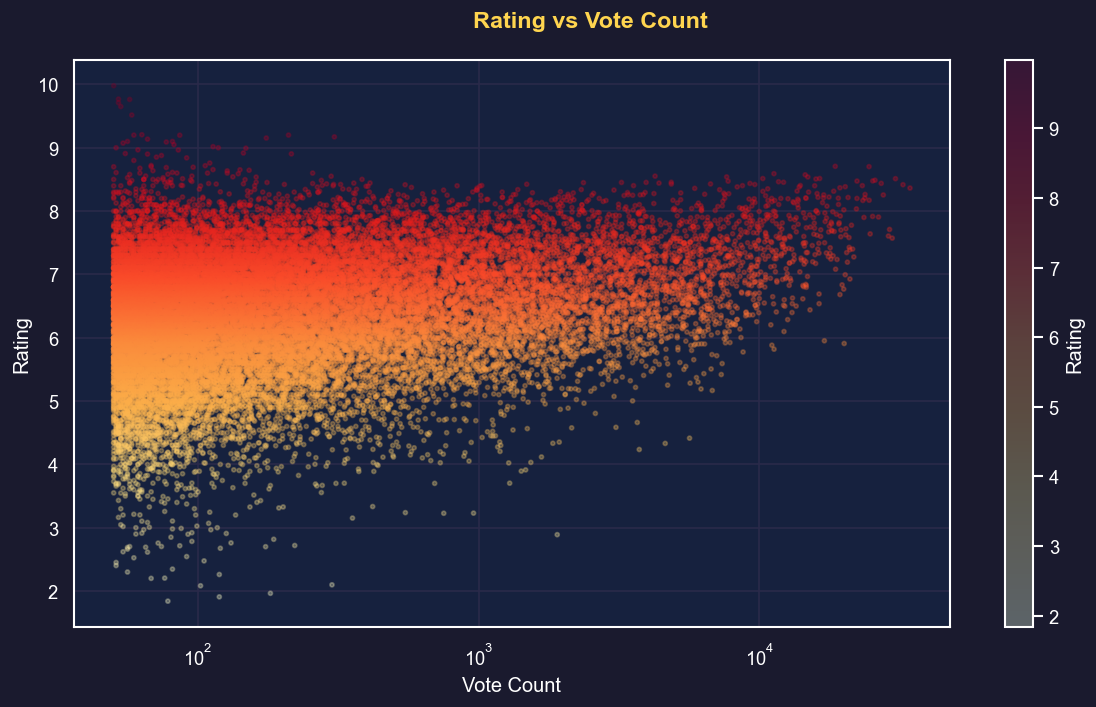

In [15]:
scatter_m = movies[(movies['vote_average'] > 0) & (movies['vote_count'] > 0)]

fig, ax = plt.subplots(figsize=(10, 6))
fig.suptitle('Rating vs Vote Count', fontsize=14, fontweight='bold', color='#ffd54f')
sc = ax.scatter(scatter_m['vote_count'], scatter_m['vote_average'],
                alpha=0.3, s=6, c=scatter_m['vote_average'], cmap='YlOrRd')
plt.colorbar(sc, ax=ax, label='Rating')
ax.set_xlabel('Vote Count')
ax.set_ylabel('Rating')
ax.set_xscale('log')
plt.tight_layout()
plt.show()

## 2.7 Runtime Distribution

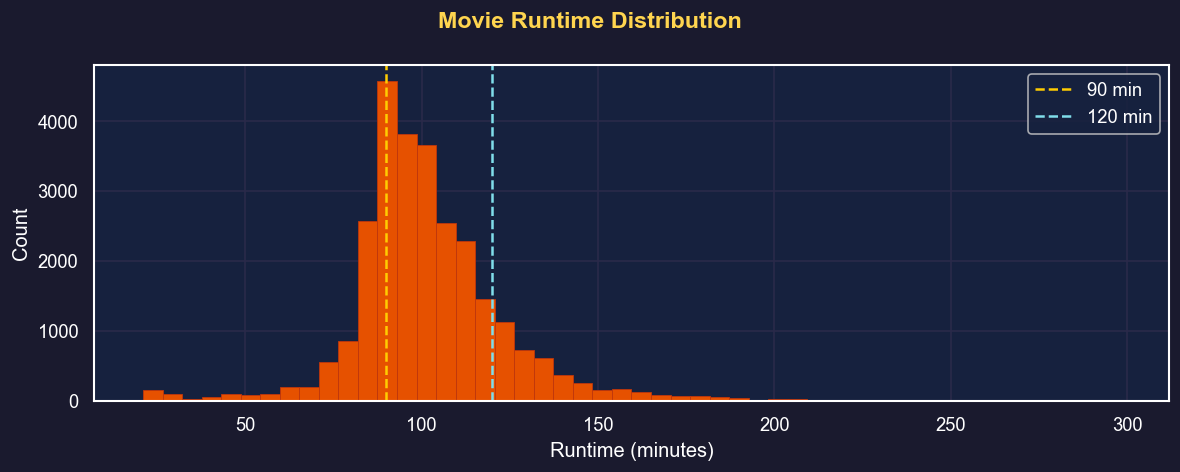

Median runtime: 99 min  |  Mean: 102 min


In [16]:
runtime = movies[(movies['runtime'] > 20) & (movies['runtime'] < 300)]['runtime']

fig, ax = plt.subplots(figsize=(10, 4))
fig.suptitle('Movie Runtime Distribution', fontsize=14, fontweight='bold', color='#ffd54f')
ax.hist(runtime, bins=50, color='#e65100', edgecolor='#bf360c', linewidth=0.5)
ax.axvline(90, color='#ffcc02', linestyle='--', linewidth=1.5, label='90 min')
ax.axvline(120, color='#80deea', linestyle='--', linewidth=1.5, label='120 min')
ax.set_xlabel('Runtime (minutes)')
ax.set_ylabel('Count')
ax.legend()
plt.tight_layout()
plt.show()
print(f'Median runtime: {runtime.median():.0f} min  |  Mean: {runtime.mean():.0f} min')

---
# 📋 Summary

In [17]:
print('=== ANIME DATASET ===')
print(f'  Total entries       : {len(anime):,}')
print(f'  Scored entries      : {anime["score"].notna().sum():,}')
print(f'  Avg score           : {anime["score"].mean():.2f}')
print(f'  Unique genres       : {anime["genres"].dropna().str.split(", ").explode().nunique()}')
print(f'  Unique types        : {anime["type"].nunique()}')
print(f'  Unique studios      : {anime["studios"].dropna().str.split(", ").explode().nunique()}')

print()
print('=== MOVIE DATASET (filtered) ===')
print(f'  Raw rows            : {len(movies_raw):,}')
print(f'  After quality filter: {len(movies):,}')
print(f'  Avg rating          : {movies[movies["vote_average"]>0]["vote_average"].mean():.2f}')
print(f'  Unique genres       : {movies["genres"].dropna().str.split(", ").explode().nunique()}')
print(f'  Unique languages    : {movies["original_language"].nunique()}')
print(f'  Movies with revenue : {(movies["revenue"]>0).sum():,}')

=== ANIME DATASET ===
  Total entries       : 30,763
  Scored entries      : 20,358
  Avg score           : 6.41
  Unique genres       : 79
  Unique types        : 10
  Unique studios      : 1439

=== MOVIE DATASET (filtered) ===
  Raw rows            : 1,525,723
  After quality filter: 27,981
  Avg rating          : 6.41
  Unique genres       : 19
  Unique languages    : 80
  Movies with revenue : 10,750
